<a href="https://colab.research.google.com/github/liverpoolisheart/2026linear-algebra-/blob/main/%EC%A4%91%EA%B0%84%EA%B3%A0%EC%82%AC_transform.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon

In [ ]:
INF = 1000 #그림판 크기
LEN = 100 #처음 사각형의 크기

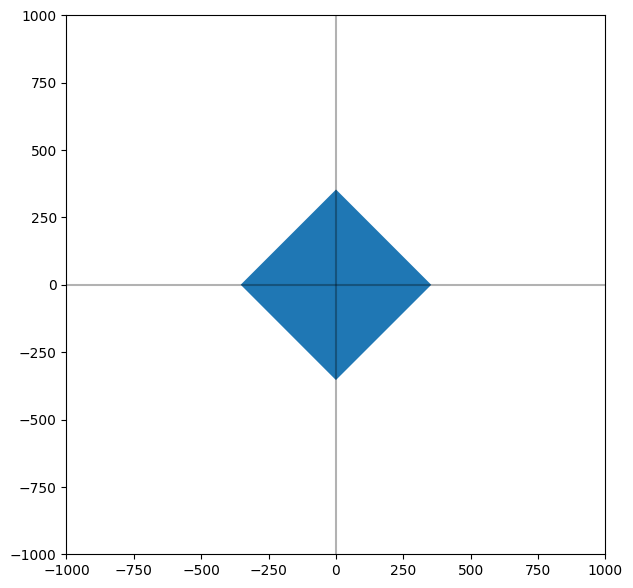

In [ ]:
#그림판 선언 및 크기 설정
fig , ax = plt.subplots(figsize = (7,7))
#fig(그림을 담는 전체 종이), ax(종이 위에서 실제로 그래프를 그리는 영역)




# 축 그리기
draw_axis(ax)

#물체 그리기
draw_object(ax)

plt.show()

In [ ]:
def draw_axis(ax):
  ax.axhline(0,color = 'black',alpha=0.3) # x-axis line
  ax.axvline(0,color = 'black',alpha=0.3) # y-axis line
  ax.set_xlim(-INF,INF)
  ax.set_ylim(-INF,INF)
  ax.set_aspect('equal') #정사각형 모형으로 backboard

In [ ]:
def draw_object(ax):
  p1 = np.array([0,0])
  p2 = np.array([LEN,0])
  p3 = np.array([LEN,LEN])
  p4 = np.array([0,LEN])

  draw_rectangle(ax,p1,p2,p3,p4)
  draw_cockpit(ax,p1,p2,p3,p4)



In [ ]:
def draw_rectangle(ax,p1,p2,p3,p4): #ax = 도형을 그릴 그래프의 영역
  my_polygon = Polygon([p1,p2,p3,p4]) #polygon은 다각형 객체를 만드는 기능
  ax.add_patch(my_polygon) #윗줄에서 만든 다각형을 ax라는 그래프 영역에 추가

In [ ]:
def draw_cockpit(ax,p1,p2,p3,p4):
  #위치 조정
  q1 = translate(p1,-LEN/2,-LEN/2)
  q2 = translate(p2,-LEN/2,-LEN/2)
  q3 = translate(p3,-LEN/2,-LEN/2)
  q4 = translate(p4,-LEN/2,-LEN/2)

  #크기 조정 s = 5
  s=5
  q1 = scale(q1,s,s)
  q2 = scale(q2,s,s)
  q3 = scale(q3,s,s)
  q4 = scale(q4,s,s)

  # #회전 변환
  q1 = rotate(q1,3.14/4.0) #파이/4
  q2 = rotate(q2,3.14/4.0)
  q3 = rotate(q3,3.14/4.0)
  q4 = rotate(q4,3.14/4.0)

  draw_rectangle(ax,q1,q2,q3,q4)

In [ ]:
#translate 구현
#점 p를 x축 방향으로 dx만큼, y축 방향으로 dy만큼 이동시킨 점 p를 구할 것
# q = T(dx,dy) p1

def translate(p,dx,dy):
  #1. 동차좌표계로 전환
  hp = np.array([p[0],p[1],1.0])

  #2. 이동 변환 행렬 생성
  m = np.array([[1.0,0.0,dx],[0.0,1.0,dy],[0.0,0.0,1.0]])

  #3. 행렬과 벡터의 곱
  q = np.dot(m,hp)

  #4. 2차원 좌표계로 변환
  q = np.array([q[0],q[1]])
  return q

In [ ]:
def scale(q,sx,sy):

  hp = np.array([q[0],q[1],1.0])

  m = np.array([[sx,0.0,0.0],[0.0,sy,0.0],[0.0,0.0,1.0]])

  q = np.dot(m,hp)

  q = np.array(q[0],q[1])

  return q


In [ ]:
def rotate(q,theta):
  hp = np.array([q[0],q[1],1.0])
  m = np.array([[np.cos(theta),-np.sin(theta),0.0],[np.sin(theta),np.cos(theta),0.0],[0.0,0.0,1.0]])
  q = np.dot(m,hp)
  # numpy에서 삼각함수도 제공함. 그리고 각도는 반드시 라디안을 사용해야함. 3.14/n ex) 60도 = 3.14/3.0
  q = np.array([q[0],q[1]]) #q[2]를 버리기 위해.
  return q